<a href="https://colab.research.google.com/github/SujitVakkalanka1/DLAC/blob/main/DLAC_Skill_1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
!pip install -q ultralytics

In [4]:
import cv2
import matplotlib.pyplot as plt
from ultralytics import YOLO
from google.colab import files
from IPython.display import display

print("=" * 60)
print("       VISIONPORT OBJECT DETECTION SYSTEM")
print("=" * 60)


       VISIONPORT OBJECT DETECTION SYSTEM


In [5]:
print("\nUpload a real photograph...")
uploaded = files.upload()

image_path = list(uploaded.keys())[0]



Upload a real photograph...


Saving istockphoto-2222928140-612x612.jpg to istockphoto-2222928140-612x612.jpg


In [6]:
print("\nLoading YOLOv8 pretrained model...")
model = YOLO("yolov8n.pt")

print("Model loaded successfully!")


Loading YOLOv8 pretrained model...
Model loaded successfully!


In [7]:
image = cv2.imread(image_path)

if image is None:
    raise ValueError("Image could not be loaded!")

image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

print("\nImage Acquisition Completed")
print("Original Image Size:", image_rgb.shape)

# 6. OBJECT DETECTION / INFERENCE
print("\nPerforming Object Detection...")

results = model.predict(
    source=image_path,
    conf=0.25,
    imgsz=640,
    verbose=False
)


Image Acquisition Completed
Original Image Size: (408, 612, 3)

Performing Object Detection...


In [8]:
output_image = results[0].plot()
output_image = cv2.cvtColor(output_image, cv2.COLOR_BGR2RGB)

In [10]:
print("\nOBJECT DETECTION RESULTS")
print("-" * 50)

boxes = results[0].boxes

if boxes is not None and len(boxes) > 0:

    for i, box in enumerate(boxes):
        class_id = int(box.cls[0])
        confidence = float(box.conf[0])
        object_name = model.names[class_id]

        x1, y1, x2, y2 = map(int, box.xyxy[0])

        print(f"{i+1}. Object: {object_name}")
        print(f"   Confidence: {confidence*100:.2f}%")
        print(f"   Bounding Box: ({x1}, {y1}, {x2}, {y2})")

else:
    print("No objects detected.")



OBJECT DETECTION RESULTS
--------------------------------------------------
1. Object: car
   Confidence: 74.79%
   Bounding Box: (288, 279, 349, 330)
2. Object: bus
   Confidence: 67.51%
   Bounding Box: (406, 193, 480, 270)
3. Object: person
   Confidence: 67.41%
   Bounding Box: (216, 374, 249, 407)
4. Object: car
   Confidence: 67.19%
   Bounding Box: (507, 257, 564, 308)
5. Object: truck
   Confidence: 66.02%
   Bounding Box: (330, 330, 409, 407)
6. Object: car
   Confidence: 64.48%
   Bounding Box: (0, 370, 46, 407)
7. Object: car
   Confidence: 63.08%
   Bounding Box: (271, 243, 316, 279)
8. Object: car
   Confidence: 53.74%
   Bounding Box: (94, 282, 157, 336)
9. Object: motorcycle
   Confidence: 48.29%
   Bounding Box: (120, 371, 147, 405)
10. Object: truck
   Confidence: 46.73%
   Bounding Box: (157, 240, 207, 306)
11. Object: truck
   Confidence: 46.56%
   Bounding Box: (36, 290, 88, 356)
12. Object: car
   Confidence: 44.60%
   Bounding Box: (477, 219, 517, 255)
13. Object

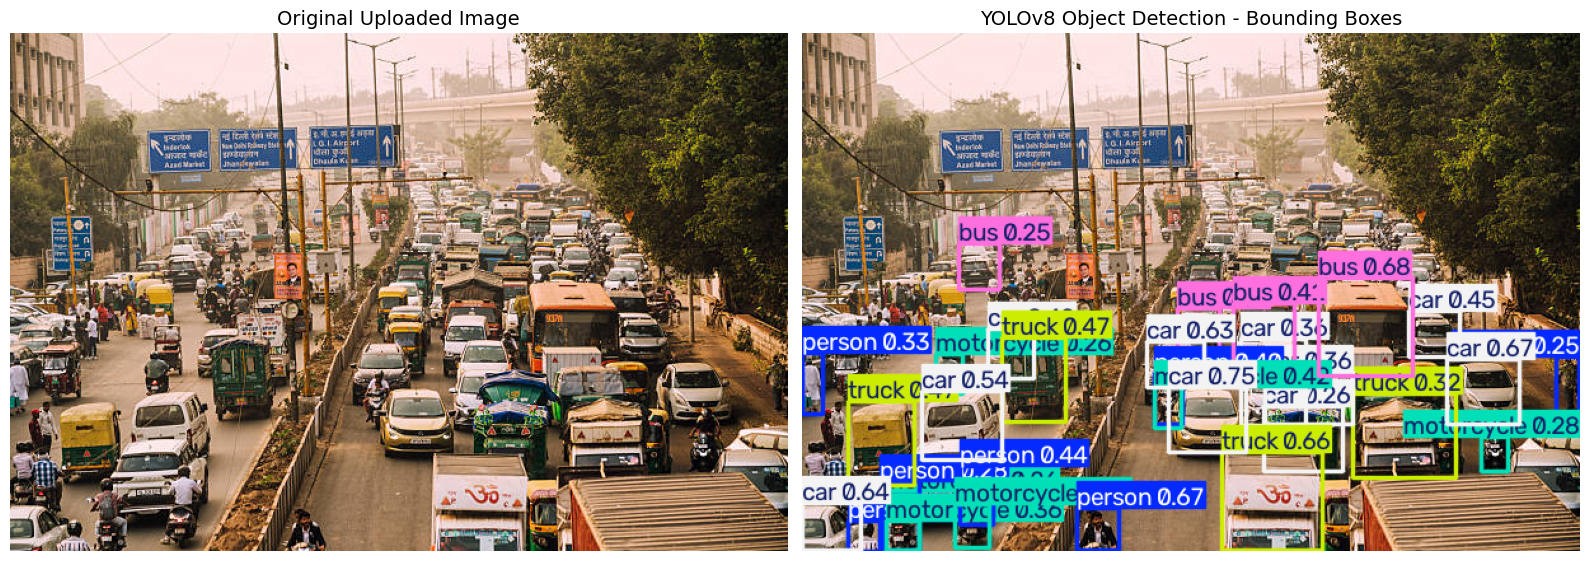

In [11]:
plt.figure(figsize=(16, 8))

plt.subplot(1, 2, 1)
plt.imshow(image_rgb)
plt.title("Original Uploaded Image", fontsize=14)
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(output_image)
plt.title("YOLOv8 Object Detection - Bounding Boxes", fontsize=14)
plt.axis("off")

plt.tight_layout()
plt.show()

In [12]:
output_path = "VisionPort_Detection_Output.jpg"

cv2.imwrite(
    output_path,
    cv2.cvtColor(output_image, cv2.COLOR_RGB2BGR)
)


True

In [13]:
print("\n" + "=" * 60)
print("           VISIONPORT SYSTEM REPORT")
print("=" * 60)

print("Image Acquisition       : SUCCESS")
print("Image Preprocessing     : SUCCESS")
print("YOLOv8 Model Loading    : SUCCESS")
print("Object Detection        : SUCCESS")
print("Bounding Box Generation: SUCCESS")
print("Output Visualization    : SUCCESS")
print("Total Objects Detected :", len(boxes))
print("=" * 60)
print("VISIONPORT PIPELINE COMPLETED!")

# 12. DOWNLOAD OUTPUT IMAGE
files.download(output_path)


           VISIONPORT SYSTEM REPORT
Image Acquisition       : SUCCESS
Image Preprocessing     : SUCCESS
YOLOv8 Model Loading    : SUCCESS
Object Detection        : SUCCESS
Bounding Box Generation: SUCCESS
Output Visualization    : SUCCESS
Total Objects Detected : 31
VISIONPORT PIPELINE COMPLETED!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>